# MRIQC

**Author:** Monika Doerig

**Date:** 6 May 2025

**License:** 
<div style="margin-top: 10px;">
    <a href="https://opensource.org/licenses/MIT" target="_blank" style="color: #0066cc;">
        <i class="fas fa-balance-scale"></i> MIT License
    </a>
</div>


**Note:** If this notebook uses neuroimaging tools from Neurocontainers, those tools retain their original licenses. Please see <a href="https://neurodesk.org/overview/how-to-cite-us/" target="_blank" style="color: #0066cc;">Neurodesk citation guidelines</a> for details.

### Citation and Resources:

#### Tools included in this workflow

__MRIQC__:

- Esteban O, Birman D, Schaer M, Koyejo OO, Poldrack RA, Gorgolewski KJ; MRIQC: Advancing the Automatic Prediction of Image Quality in MRI from Unseen Sites; PLOS ONE 12(9):e0184661; doi:[10.1371/journal.pone.0184661](https://doi.org/10.1371/journal.pone.0184661)

- The documentation of this project is found [here](https://mriqc.readthedocs.io/).
  

#### Dataset
__Data from OpenNeuro:__ Flanker Dataset

- Kelly AMC and Uddin LQ and Biswal BB and Castellanos FX and Milham MP (2018). Flanker task (event-related). [OpenNeuro Dataset ds000102](https://openneuro.org/datasets/ds000102/versions/00001/). [Dataset] doi: null
- Kelly AM, Uddin LQ, Biswal BB, Castellanos FX, Milham MP. Competition between functional brain networks mediates behavioral variability. Neuroimage. 2008 Jan 1;39(1):527-37. doi: [10.1016/j.neuroimage.2007.08.008](https://doi.org/10.1016/j.neuroimage.2007.08.008). Epub 2007 Aug 23. PMID: 17919929.
- Mennes, M., Kelly, C., Zuo, X.N., Di Martino, A., Biswal, B.B., Castellanos, F.X., Milham, M.P. (2010). Inter-individual differences in resting-state functional connectivity predict task-induced BOLD activity. Neuroimage, 50(4):1690-701. doi: [10.1016/j.neuroimage.2010.01.002](https://doi.org/10.1016/j.neuroimage.2010.01.002). Epub 2010 Jan 15. Erratum in: Neuroimage. 2011 Mar 1;55(1):434
- Mennes, M., Zuo, X.N., Kelly, C., Di Martino, A., Zang, Y.F., Biswal, B., Castellanos, F.X., Milham, M.P. (2011). Linking inter-individual differences in neural activation and behavior to intrinsic brain dynamics. Neuroimage, 54(4):2950-9. doi: [10.1016/j.neuroimage.2010.10.046](https://doi.org/10.1016/j.neuroimage.2010.10.046)

## Introduction
In this notebook, we demonstrate the use of MRIQC for automated MRI quality assessment and include examples of the visual reports generated.
By the end of this notebook, you will be able to:
- Run MRIQC at the single-participant level
- Run MRIQC at the group level

MRIQC is an open-source tool that extracts no-reference image quality metrics (IQMs) from structural (T1w and T2w), functional, and diffusion MRI data. It follows the Brain Imaging Data Structure (BIDS) standard and is built on a modular nipype workflow, integrating tools such as ANTs and AFNI while keeping preprocessing minimal to preserve the integrity of the original data. Reliability is continuously validated against diverse datasets to ensure robustness across varying acquisition parameters and subject populations.

> **Note:** This notebook assumes your data is already in BIDS format. If you are 
> running on an HPC, note that MRIQC has its `$HOME` variable hardcoded to 
> `/home/mriqc`, which can cause problems on some systems. Run this before MRIQC:
```bash
export neurodesk_singularity_opts="--home $HOME:/home"
```

## Load MRIQC and import python libraries

In [1]:
%%capture
! pip install beautifulsoup4

In [2]:
from bs4 import BeautifulSoup
from IPython.display import HTML, display
import os

In [3]:
import module
await module.load('mriqc/24.0.2') 
await module.list()

['mriqc/24.0.2']

In [4]:
!mriqc -h

usage: mriqc [-h] [--version] [-v] [--species {human,rat}]
             [--participant-label PARTICIPANT_LABEL [PARTICIPANT_LABEL ...]]
             [--bids-filter-file PATH] [--session-id [SESSION_ID ...]]
             [--run-id [RUN_ID ...]] [--task-id [TASK_ID ...]]
             [-m [{T1w,T2w,bold,dwi} ...]] [--dsname DSNAME]
             [--bids-database-dir PATH] [--bids-database-wipe]
             [--no-datalad-get] [--nprocs NPROCS]
             [--omp-nthreads OMP_NTHREADS] [--mem MEMORY_GB] [--testing] [-f]
             [--pdb] [-w WORK_DIR] [--verbose-reports] [--reports-only]
             [--write-graph] [--dry-run] [--resource-monitor]
             [--use-plugin USE_PLUGIN] [--crashfile-format {txt,pklz}]
             [--no-sub] [--email EMAIL] [--webapi-url WEBAPI_URL]
             [--webapi-port WEBAPI_PORT] [--upload-strict] [--notrack]
             [--ants-float] [--ants-settings ANTS_SETTINGS]
             [--min-dwi-length MIN_LEN_DWI] [--min-bold-length MIN_LEN_BOLD]

## Data preparation

In [3]:
%%bash
set -euo pipefail
# Retry transient network failures, then fail the cell instead of continuing without data.
retry() { for i in 1 2 3 4 5; do "$@" && return 0; echo "Attempt $i failed: $*" >&2; [ "$i" -lt 5 ] && sleep $((i * 15)); done; return 1; }
[ -d ds000102 ] || retry datalad install https://github.com/OpenNeuroDatasets/ds000102.git
cd ds000102 && retry datalad get sub-01 sub-02 sub-03

Cloning:   0%|                             | 0.00/2.00 [00:00<?, ? candidates/s]
Enumerating: 0.00 Objects [00:00, ? Objects/s]
                                              
Counting:   0%|                               | 0.00/27.0 [00:00<?, ? Objects/s]
                                                                                
Compressing:   0%|                            | 0.00/23.0 [00:00<?, ? Objects/s]
                                                                                
Receiving:   0%|                             | 0.00/2.15k [00:00<?, ? Objects/s]
                                                                                
Resolving:   0%|                                | 0.00/537 [00:00<?, ? Deltas/s]
[INFO   ] Remote origin not usable by git-annex; setting annex-ignore           
[INFO   ] https://github.com/OpenNeuroDatasets/ds000102.git/config download failed: Not Found 
[INFO   ] access to 1 dataset sibling s3-PRIVATE not auto-enabled, enable with:
| 

The following section outlines key MRIQC command-line options used in this analysis. These include required positional arguments for specifying input and output directories, as well as optional flags for performance optimization and report generation. For a complete list of available options, refer to the [official documentation](https://mriqc.readthedocs.io/en/latest/usage.html#positional-arguments).


#### Positional Arguments
- `bids_dir`: The root folder of a BIDS valid dataset (sub-XXXXX folders should be found at the top level in this folder).

- `output_dir`:  The directory where the output files should be stored. If you are running group level analysis this folder should be prepopulated with the results of the participant level analysis.

- `analysis_level`:  Possible choices: participant, group

Level of the analysis that will be performed. Multiple participant level analyses can be run independently (in parallel) using the same output_dir.

- `-v, --verbose`: Increases log verbosity for each occurrence, debug level is `-vvv`.

#### Options to handle performance
- `--nprocs, --n_procs, --n_cpus, -n-cpus`
Maximum number of simultaneously running parallel processes executed by MRIQC (e.g., several instances of ANTs’ registration). However, when --nprocs is greater or equal to the --omp-nthreads option, it also sets the maximum number of threads that simultaneously running processes may aggregate (meaning, with --nprocs 16 --omp-nthreads 8 a maximum of two 8-CPU-threaded processes will be running at a given time). Under this mode of operation, --nprocs sets the maximum number of processors that can be assigned work within an MRIQC job, which includes all the processors used by currently running single- and multi-threaded processes. If None, the number of CPUs available will be automatically assigned (which may not be what you want in, e.g., shared systems like a HPC cluster.

- `--mem, --mem_gb, --mem-gb`: Upper bound memory limit for MRIQC processes.

#### Instrumental options
- `-w, --work-dir`:
Path where intermediate results should be stored.

- `--verbose-reports`: Generate verbose HTML reports with additional details
- `--no-sub`: Turn off submission of anonymized quality metrics to MRIQC’s metrics repository.

<div style="background-color: rgba(245, 158, 11, 0.1); padding: 10px; border-radius: 5px; border: 2px solid #f59e0b;">
    <div style="background-color: #f59e0b; padding: 5px; border-radius: 5px; font-weight: bold;">
        <span style="font-size: 15px; color: #f59e0b; background-color: #fff; border-radius: 50%; width: 20px; height: 20px; display: inline-block; text-align: center; line-height: 20px;">
            !
        </span> <span style="color: white;">Warning:</span>
    </div>
    <p style="margin: 10px 0;">
        <code>--no-sub</code> and <code>--notrack</code> may be necessary in 
        environments with limited internet access, where automatic submission of 
        quality metrics to MRIQC's web server and tracking data to NiPreps 
        developers may fail or trigger runtime errors.
    </p>
</div>

### Participant-level Analysis

In [4]:
%%bash

# Exit immediately if a command fails
set -e

# Set the number of threads for ITK (Image Processing Toolkit) to use
export ITK_GLOBAL_DEFAULT_NUMBER_OF_THREADS=6
# Set the directory for matplotlib configuration to avoid conflicts
export MPLCONFIGDIR=~/matplotlib-mpldir

# Run MRIQC
mriqc ds000102 \
        MRIQC \
        participant \
        --participant-label sub-01 sub-02 sub-03 \
        --no-sub \
        --work-dir MRIQC_workdir \
        --nprocs 6 \
        --mem-gb 10 \
        --verbose-reports \
        -v

------------------------------------------------------------------
  Running MRIQC version 24.1.0.dev0+gd5b13cb5.d20240826
  ----------------------------------------------------------------

  NOTICE
  Copyright © The NiPreps Developers.
  
  This product includes software developed by
  the NiPreps Community (https://nipreps.org/).
  
  Portions of this software were developed at the Department of
  Psychology at Stanford University, Stanford, CA, US.
  
  This software contains code ultimately derived from the
  PCP Quality Assessment Protocol (QAP;
  http://preprocessed-connectomes-project.org/quality-assessment-protocol)
  by C. Craddock, S. Giavasis, D. Clark, Z. Shezhad, and J. Pellman.
  
  This software is also distributed as a Docker container image.
  The bootstrapping file for the image ("Dockerfile") is licensed
  under the MIT License.

  ----------------------------------------------------------------

  * BIDS dataset path: /home/jovyan/Git_repositories/neurodeskedu/book

/opt/conda/lib/python3.11/site-packages/nilearn/plotting/displays/_slicers.py:420: UserWarning: empty mask
  xmin_, xmax_, ymin_, ymax_, zmin_, zmax_ = get_mask_bounds(


2026-03-09 09:37:57 | INFO     | nipype.workflow  | [Node] Finished "PlotAirmask", elapsed time 7.782994s.
2026-03-09 09:37:58 | INFO     | nipype.workflow  | [Node] Finished "PlotArtmask", elapsed time 8.062516s.


/opt/conda/lib/python3.11/site-packages/nilearn/plotting/displays/_slicers.py:420: UserWarning: empty mask
  xmin_, xmax_, ymin_, ymax_, zmin_, zmax_ = get_mask_bounds(


2026-03-09 09:37:58 | INFO     | nipype.workflow  | [Node] Setting-up "mriqc_wf.anatMRIQC.anat_report_wf.ds_report_airmask" in "/home/jovyan/Git_repositories/neurodeskedu/books/examples/workflows/MRIQC_workdir/mriqc_wf/anatMRIQC/anat_report_wf/14bda8fd024ded134cb29aaa5588034de5ac1dc8/ds_report_airmask".
2026-03-09 09:37:58 | INFO     | nipype.workflow  | [Node] Executing "ds_report_airmask" <mriqc.interfaces.DerivativesDataSink>
2026-03-09 09:37:58 | INFO     | nipype.workflow  | [Node] Finished "ds_report_airmask", elapsed time 0.013556s.
2026-03-09 09:37:58 | INFO     | nipype.workflow  | [Node] Finished "synthstrip", elapsed time 83.24745s.
2026-03-09 09:37:58 | INFO     | nipype.workflow  | [Node] Setting-up "mriqc_wf.anatMRIQC.anat_report_wf.ds_report_artmask" in "/home/jovyan/Git_repositories/neurodeskedu/books/examples/workflows/MRIQC_workdir/mriqc_wf/anatMRIQC/anat_report_wf/14bda8fd024ded134cb29aaa5588034de5ac1dc8/ds_report_artmask".
2026-03-09 09:37:58 | INFO     | nipype.wor

/opt/conda/lib/python3.11/site-packages/nilearn/plotting/displays/_slicers.py:420: UserWarning: empty mask
  xmin_, xmax_, ymin_, ymax_, zmin_, zmax_ = get_mask_bounds(


2026-03-09 09:37:58 | INFO     | nipype.workflow  | [Node] Finished "ds_report_artmask", elapsed time 0.010925s.
2026-03-09 09:37:59 | INFO     | nipype.workflow  | [Node] Finished "PlotArtmask", elapsed time 8.159047s.
2026-03-09 09:37:59 | INFO     | nipype.workflow  | [Node] Finished "synthstrip", elapsed time 83.478397s.
2026-03-09 09:37:59 | INFO     | nipype.workflow  | [Node] Finished "PlotAirmask", elapsed time 7.365819s.
2026-03-09 09:37:59 | INFO     | nipype.workflow  | [Node] Finished "PlotArtmask", elapsed time 7.520811s.
2026-03-09 09:37:59 | INFO     | nipype.workflow  | [Node] Finished "synthstrip", elapsed time 84.217287s.
2026-03-09 09:38:00 | INFO     | nipype.workflow  | [Node] Setting-up "mriqc_wf.funcMRIQC.synthstrip_wf.post_n4" in "/home/jovyan/Git_repositories/neurodeskedu/books/examples/workflows/MRIQC_workdir/mriqc_wf/funcMRIQC/synthstrip_wf/3d120471020d0ce6f0b07ecc8d6986cb5ef5fbc4/post_n4".
2026-03-09 09:38:00 | INFO     | nipype.workflow  | [Node] Setting-up

### Group-level Analysis

In [5]:
%%bash

# Exit immediately if a command fails
set -e

mriqc ds000102 \
        MRIQC \
        group \
        --no-sub \
        --work-dir MRIQC_workdir \
        --nprocs 6 \
        --mem-gb 10 \
        --verbose-reports \
        -v                           

------------------------------------------------------------------
  Running MRIQC version 24.1.0.dev0+gd5b13cb5.d20240826
  ----------------------------------------------------------------

  NOTICE
  Copyright © The NiPreps Developers.
  
  This product includes software developed by
  the NiPreps Community (https://nipreps.org/).
  
  Portions of this software were developed at the Department of
  Psychology at Stanford University, Stanford, CA, US.
  
  This software contains code ultimately derived from the
  PCP Quality Assessment Protocol (QAP;
  http://preprocessed-connectomes-project.org/quality-assessment-protocol)
  by C. Craddock, S. Giavasis, D. Clark, Z. Shezhad, and J. Pellman.
  
  This software is also distributed as a Docker container image.
  The bootstrapping file for the image ("Dockerfile") is licensed
  under the MIT License.

  ----------------------------------------------------------------

  * BIDS dataset path: /home/jovyan/Git_repositories/neurodeskedu/book

## MRIQC Visual Reports
MRIQC automatically generates individual and group-level reports to support the quality assessment of MRI data.

Individual reports include mosaic views of anatomical or functional images along various cutting planes, along with overlays like segmentation contours or motion estimates. These visuals help quickly screen for artifacts or other issues. They are especially useful for reviewing images that may have been flagged as low-quality by the automated classifier.

Group reports compile quality metrics across all subjects and display interactive scatter plots for each image quality metric (IQM). These plots make it easy to spot outliers—clicking on any point in the scatter plot refers to the corresponding individual report for that subject.

These embedded reports offer an intuitive way to explore quality metrics and support decisions about excluding or further examining specific runs or subjects.

### Anatomical Report

In [9]:
# Helper function to display MRIQC HTML reports with inline SVG figures

def display_mriqc_report(report_path):
    report_dir = os.path.dirname(report_path)
    with open(report_path) as f:
        soup = BeautifulSoup(f, 'html.parser')
    # Inline each figure where the report embeds it, and drop the "Get figure file" links:
    # both point into MRIQC/, which is not published with this page, and would 404.
    for tag in soup.find_all(class_='svg-reportlet'):
        svg_path = os.path.join(report_dir, tag.get('src') or tag.get('data', ''))
        if os.path.exists(svg_path):
            with open(svg_path) as svg_file:
                svg_soup = BeautifulSoup(svg_file.read(), 'html.parser')
                tag.replace_with(svg_soup)
    for small in soup.find_all('small'):
        if small.get_text().startswith('Get figure file'):
            small.decompose()
    for tag in soup(['button', 'nav', 'head']):
        tag.decompose()
    display(HTML(str(soup)))


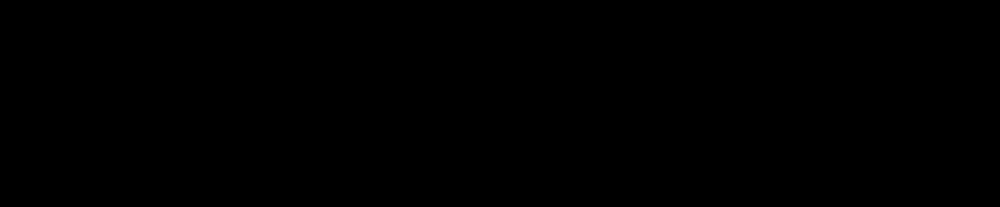
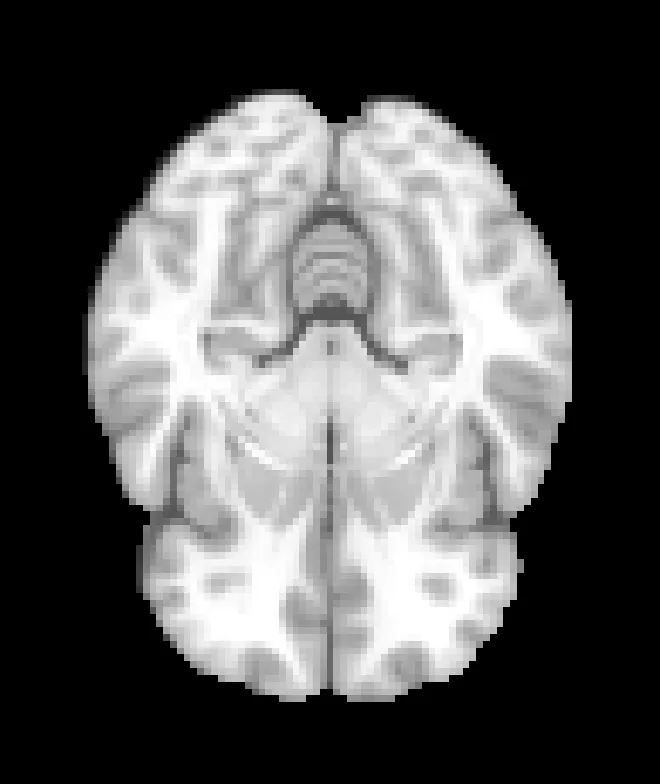
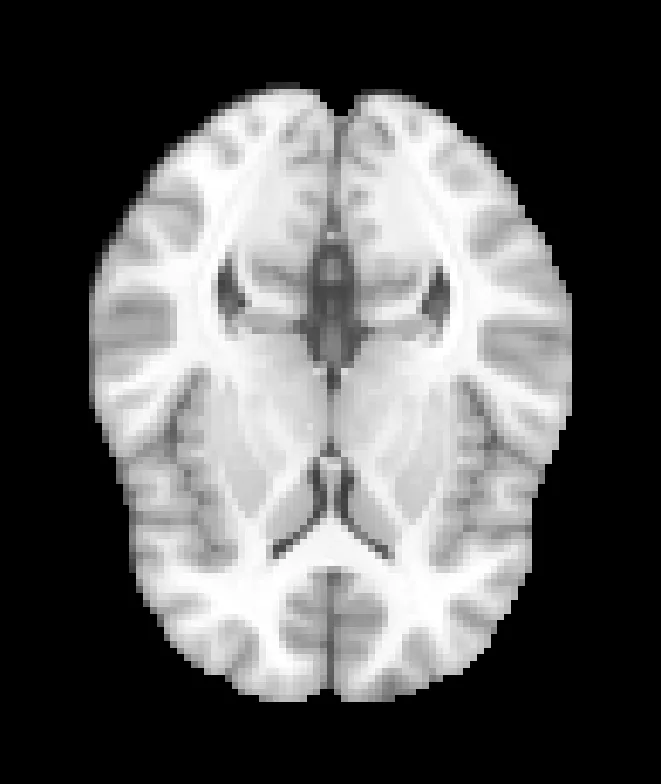
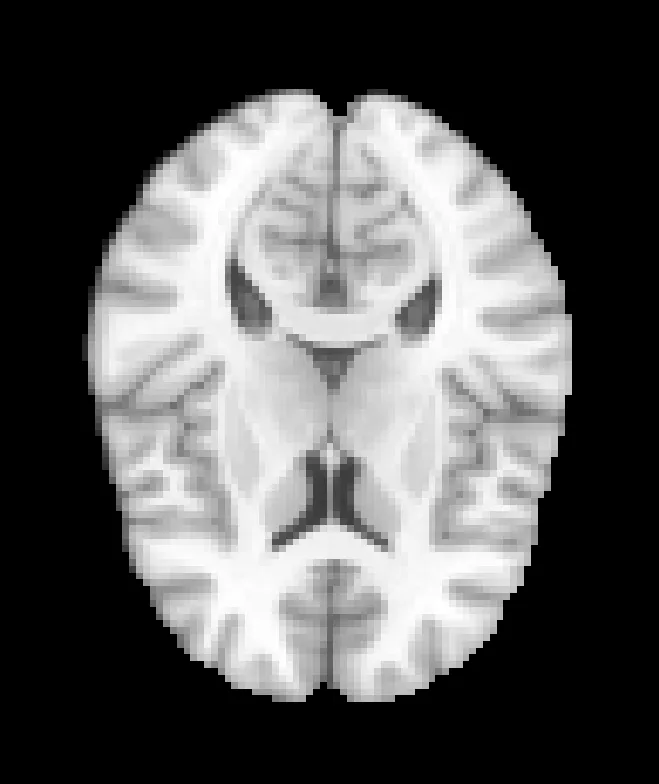
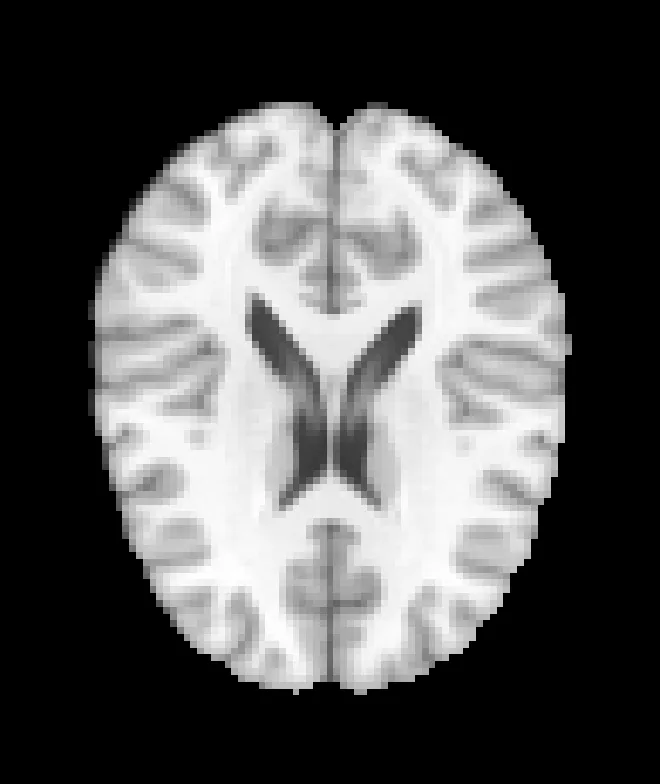
...
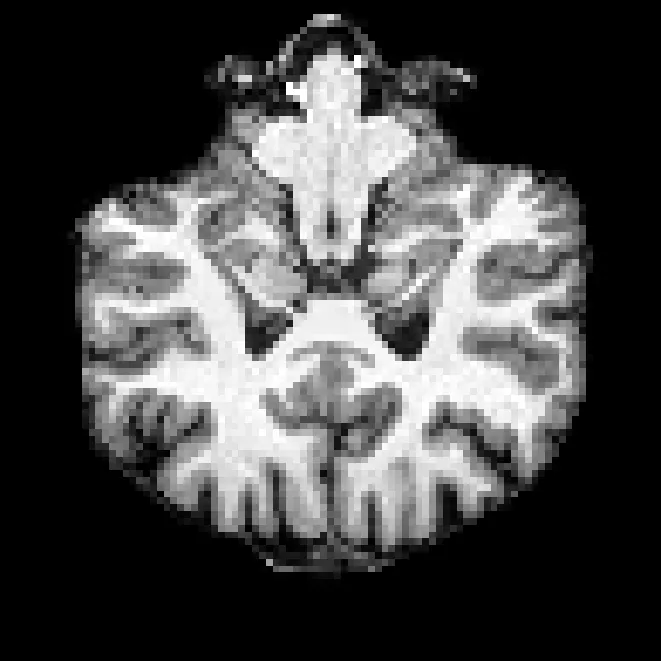
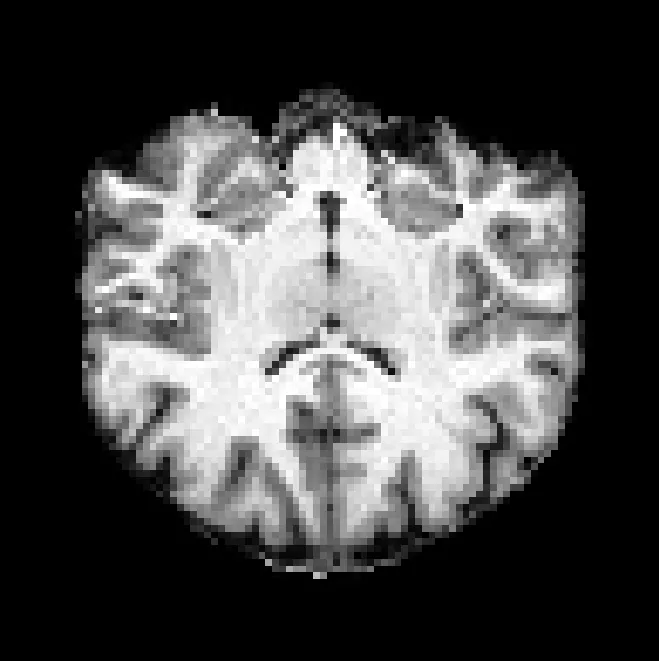
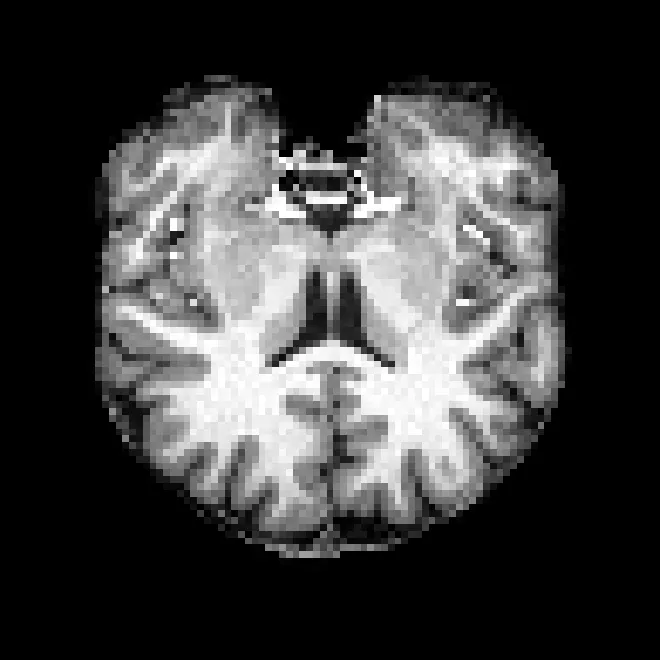
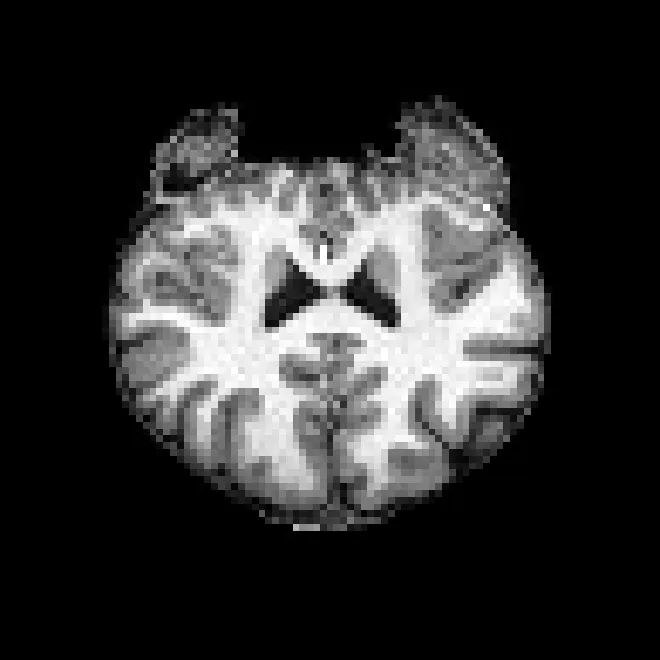
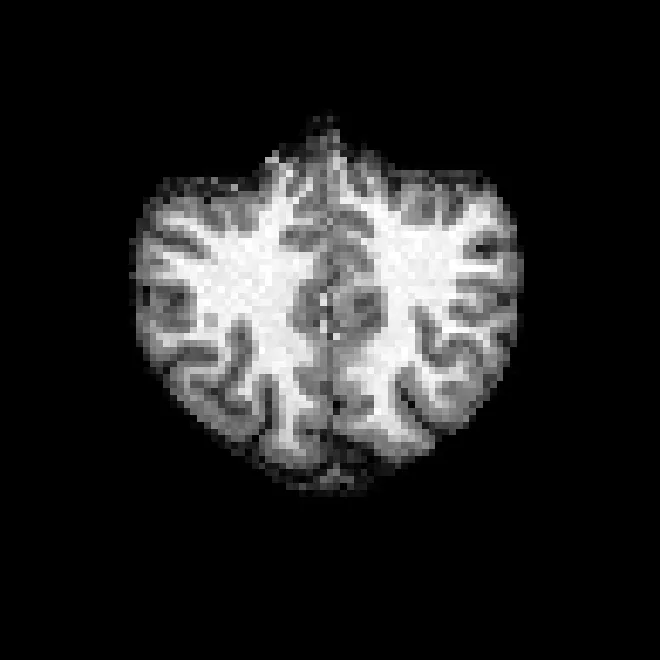

In [15]:
display_mriqc_report('./MRIQC/sub-01_T1w.html')

### Functional Report


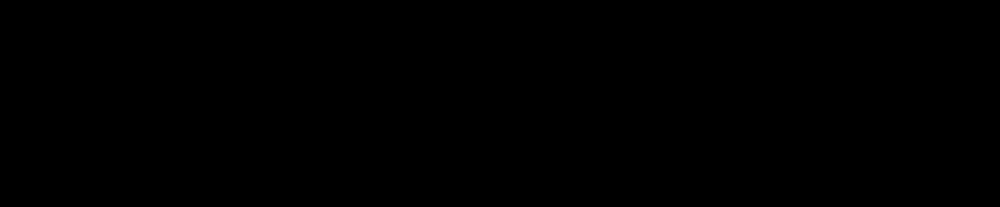
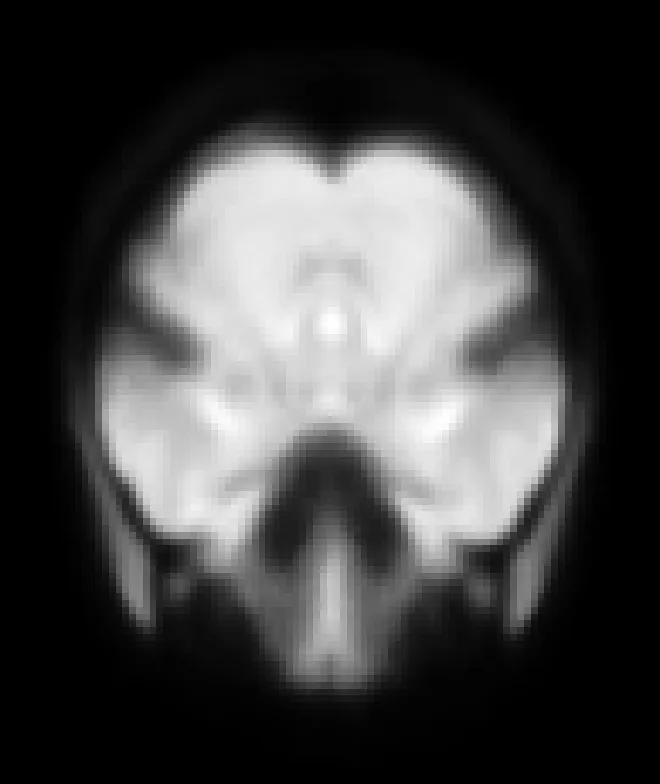
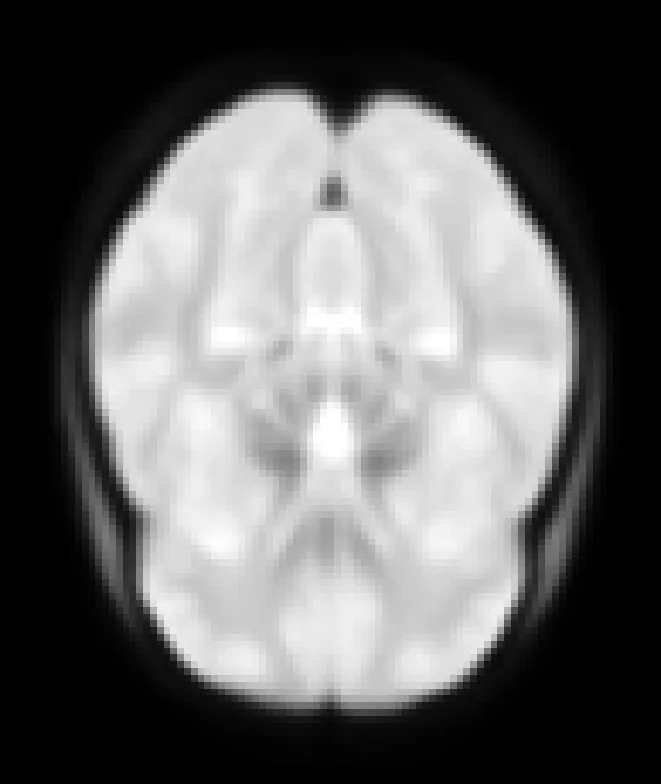
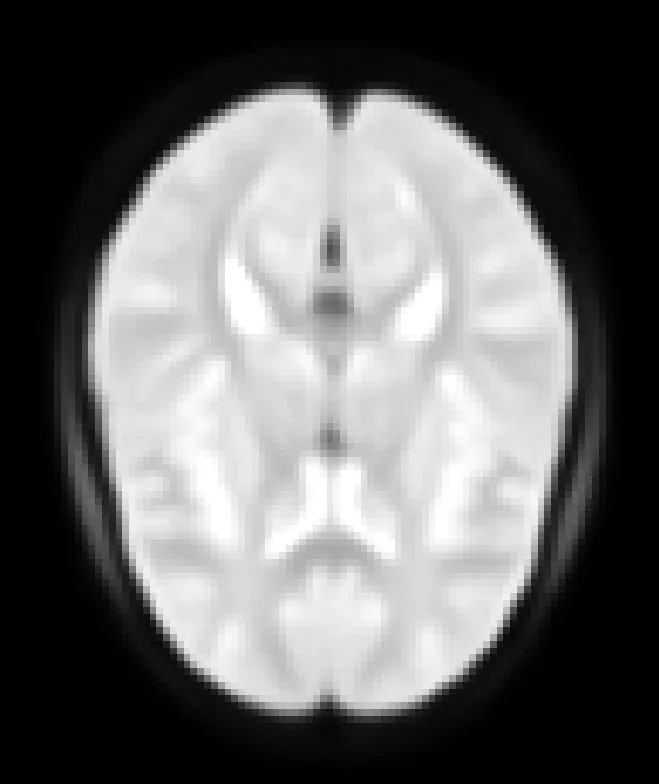
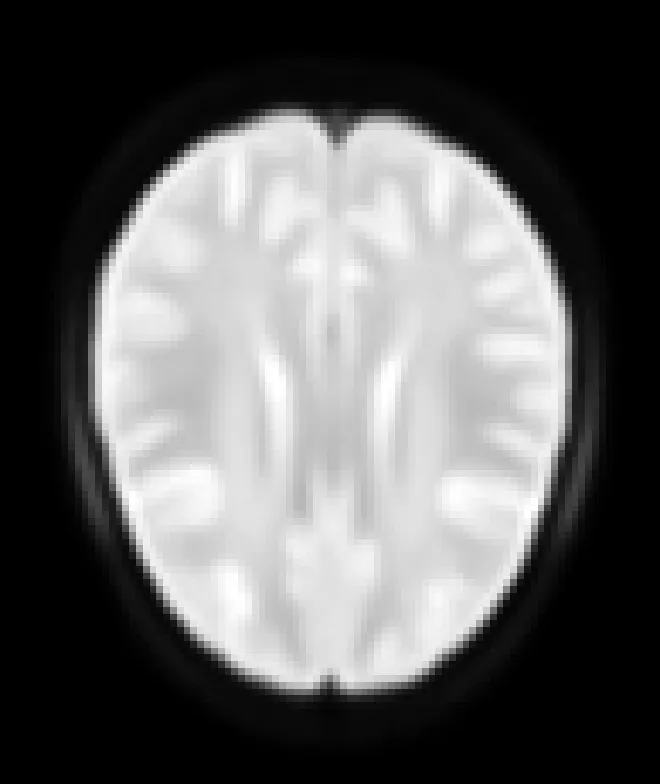
...
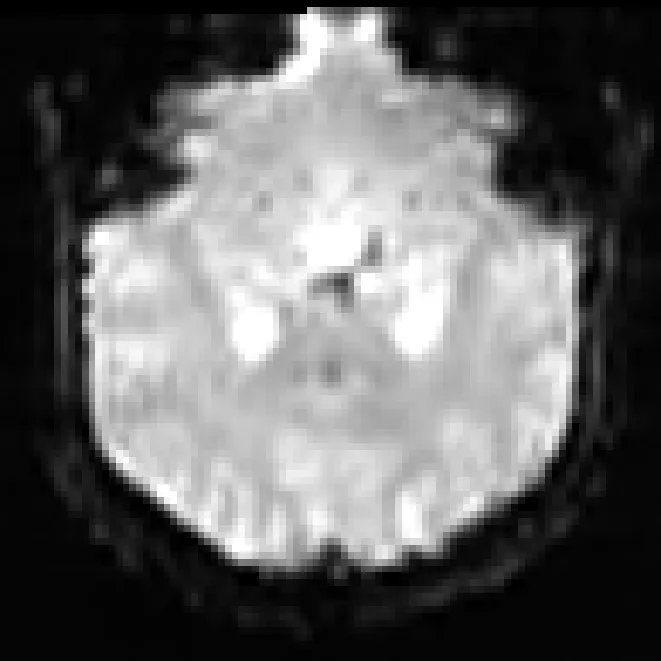
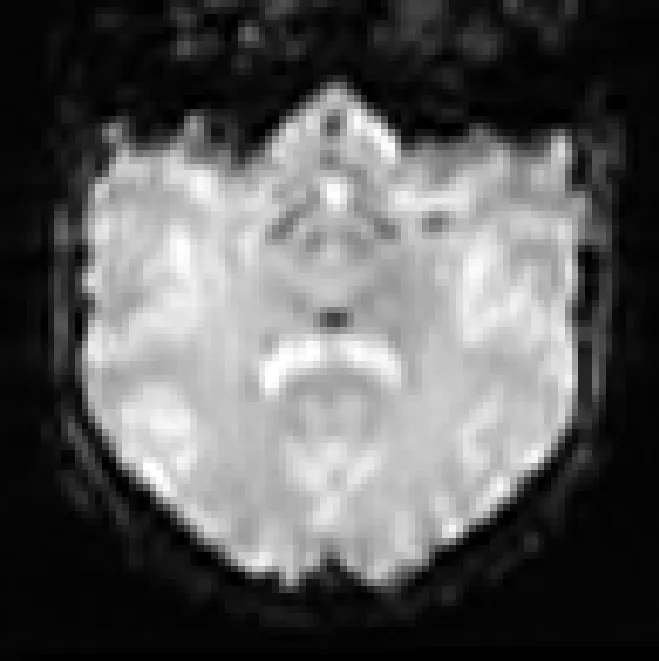
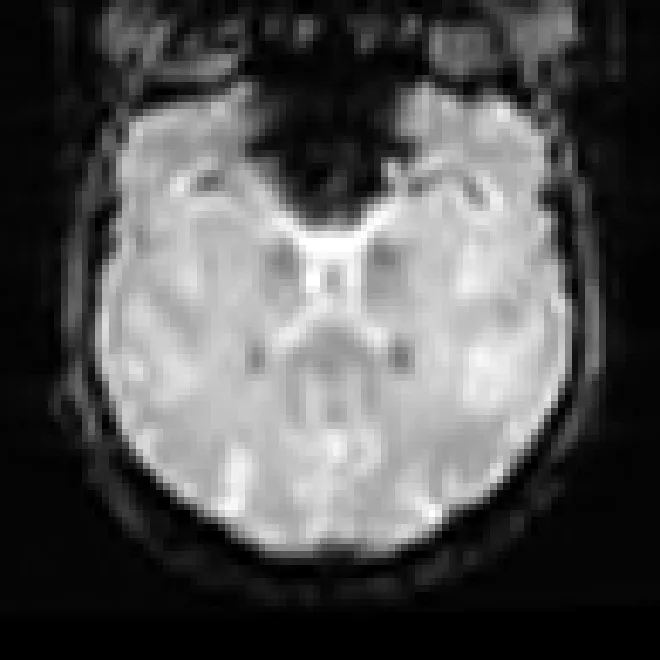
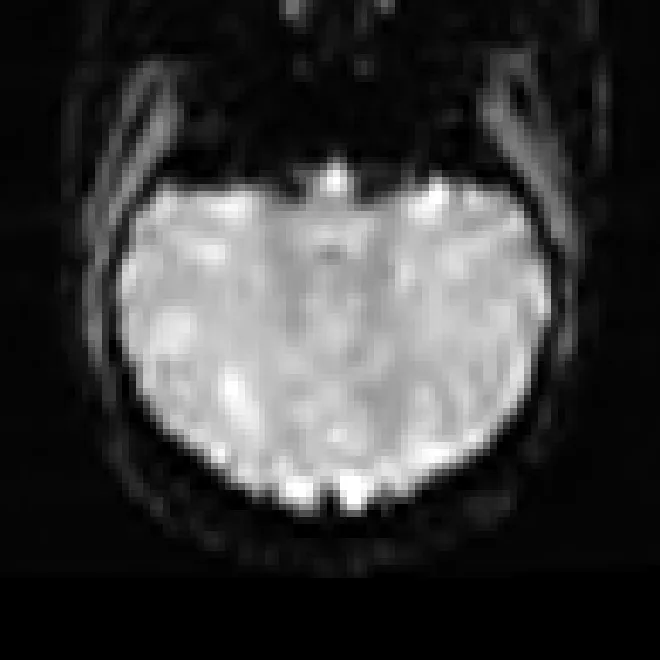
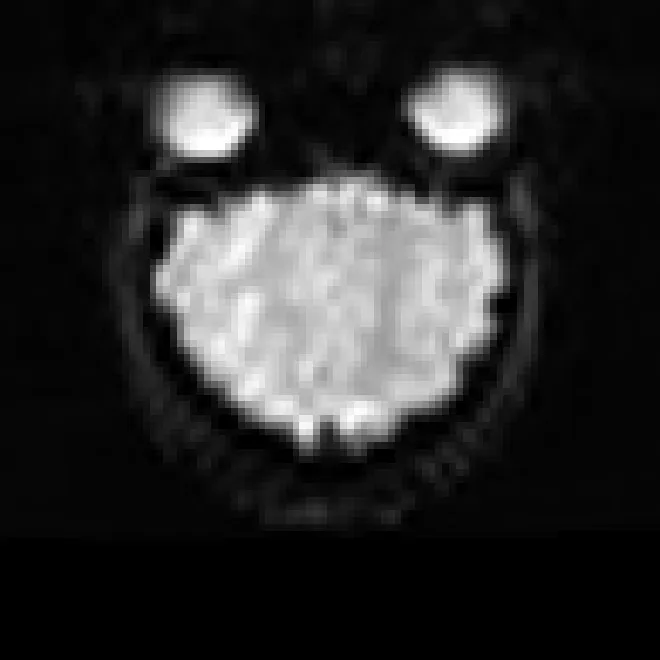

In [16]:
display_mriqc_report('./MRIQC/sub-02_task-flanker_run-1_bold.html')

### Group functional report

In [12]:
with open('./MRIQC/group_bold.html', 'r') as f:
    html = f.read()

display(HTML(html))

#### Dependencies in Jupyter/Python
- Using the package [watermark](https://github.com/rasbt/watermark) to document system environment and software versions used in this notebook, alongside the Neurodesktop version extracted from the `JUPYTER_IMAGE` or `NEURODESKTOP_VERSION` environment variables.

In [5]:
import os

%load_ext watermark

%watermark
%watermark --iversions

neurodesktop_version = (
    os.environ.get('JUPYTER_IMAGE', '').split(':')[-1] or
    os.environ.get('NEURODESKTOP_VERSION', 'unknown')
)

print(f"Neurodesktop version: {neurodesktop_version}")

Last updated: 2026-03-30T04:52:16.119630+00:00

Python implementation: CPython
Python version       : 3.13.9
IPython version      : 9.7.0

Compiler    : GCC 14.3.0
OS          : Linux
Release     : 6.6.87.2-microsoft-standard-WSL2
Machine     : x86_64
Processor   : x86_64
CPU cores   : 12
Architecture: 64bit

IPython: 9.7.0
bs4    : 4.14.3

Neurodesktop version: 2025-12-20
